In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Telco-Customer-Churn.csv")

df.columns = df.columns.str.strip()

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df.head()

C:\Users\Gohel Manoj\AppData\Local\Temp\ipykernel_7164\3958796792.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Task 1 – Count churned and non-churned customers

In [2]:
churn_counts = df["Churn"].value_counts()

print("Customer Churn Count:")
print(churn_counts)

print("\nChurned Customers:", churn_counts.get("Yes", 0))
print("Non-Churned Customers:", churn_counts.get("No", 0))

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churned Customers: 1869
Non-Churned Customers: 5174


Task 2 – Contract type vs Churn

In [3]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("Contract Type vs Customer Churn:")
display(contract_churn)

print("\nChurned Customers by Contract Type:")
print(contract_churn["Yes"])

Contract Type vs Customer Churn:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Churned Customers by Contract Type:
Contract
Month-to-month    1655
One year           166
Two year            48
Name: Yes, dtype: int64


Task 3 – Average MonthlyCharges for churned vs non-churned customers

In [4]:
churned_avg = df.loc[
    df["Churn"] == "Yes", "MonthlyCharges"
].mean()

not_churned_avg = df.loc[
    df["Churn"] == "No", "MonthlyCharges"
].mean()

print("Average Monthly Charges:")
print("Churned Customers:", round(churned_avg, 2))
print("Non-Churned Customers:", round(not_churned_avg, 2))

Average Monthly Charges:
Churned Customers: 74.44
Non-Churned Customers: 61.27


Task 4 – InternetService vs Churn bar chart

Internet Service vs Churn:


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


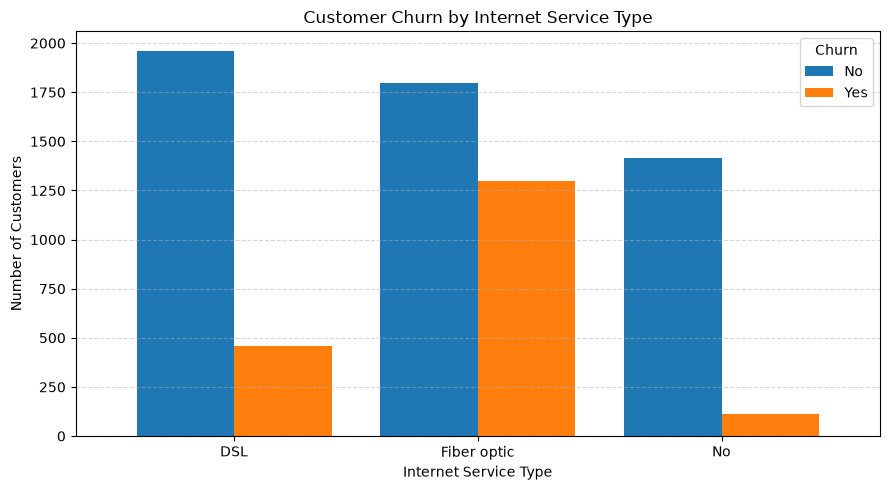

In [5]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

print("Internet Service vs Churn:")
display(internet_churn)

internet_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

plt.title("Customer Churn by Internet Service Type")
plt.xlabel("Internet Service Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Task 5 – Correlation between Tenure and Churn

In [6]:
df["Churn_Numeric"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

correlation = df["tenure"].corr(
    df["Churn_Numeric"]
)

print("Correlation between Tenure and Churn:",
      round(correlation, 4))

Correlation between Tenure and Churn: -0.3522


Explanation

Correlation measures the relationship between two variables.

Here:
- Tenure represents the number of months a customer has stayed with the company.
- Churn_Numeric represents whether the customer left the company.
- Yes = 1
- No = 0
The correlation value ranges from -1 to +1.

In [7]:
with pd.ExcelWriter("Customer_Churn_Analysis.xlsx") as writer:

    churn_counts.to_frame(
        name="Customer Count"
    ).to_excel(writer, sheet_name="Churn Summary")

    contract_churn.to_excel(
        writer, sheet_name="Contract Analysis"
    )

    internet_churn.to_excel(
        writer, sheet_name="Internet Analysis"
    )

    pd.DataFrame({
        "Customer Group": [
            "Churned", "Not Churned"
        ],
        "Average Monthly Charges": [
            churned_avg, not_churned_avg
        ]
    }).to_excel(
        writer, sheet_name="Monthly Charges", index=False
    )

    pd.DataFrame({
        "Correlation": [correlation]
    }).to_excel(
        writer, sheet_name="Correlation", index=False
    )

print("Analysis exported successfully!")

Analysis exported successfully!
